# Offset between GALAH and LAMOST

In this jupyter we investigate the offset in different parameters between GALAH and LAMOST stars used in our sample 


In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp
from scipy import stats
import astropy

#Very important import
from breidablik.interpolate.nlte import Nlte

In [116]:
# Constants

LI_ABUNDANCE_SUN = 1.05 # Asplund et al. (2009)

## Offset in Abundances of lithium

### LAMOST vs GALAH DR3

First we will try our metogology for testing offsets

In [117]:
data_path = '../../data/LAMOST_catalog/'

GALAHDR3_x_LAMOST = pd.read_csv(data_path + 'LAMOST_x_GALAHDR3.csv')

#Li_fe
#e_Li_fe


In [118]:
# Filtering criteria following Ding et al. (2024) Section IV and Gao et al. (2021):
# 1. LAMOST spectra S/N > 20
# 2. GALAH quality flags: flag_sp == 0, flag_fe_h == 0, flag_Li_fe == 0, snr_c3_iraf > 30
# 3. Discard upper limits (Lim == 0)
# 4. Uncertainty on [Li/Fe] and [Fe/H] < 0.2 dex (e_Li_fe < 0.2 and e_fe_h < 0.2)
GALAHDR3_x_LAMOST = GALAHDR3_x_LAMOST[
    (GALAHDR3_x_LAMOST['flag_fe_h'] == 0)
    & (GALAHDR3_x_LAMOST['flag_Li_fe'] == 0)
    & (GALAHDR3_x_LAMOST['snr_c3_iraf'] > 30)
    & (GALAHDR3_x_LAMOST['flag_sp'] == 0)
    & (GALAHDR3_x_LAMOST['S_N'] > 20)
    & (GALAHDR3_x_LAMOST['Lim'] == 0)  # Detections only (Ding et al. 2024 Section IV)
    & (GALAHDR3_x_LAMOST['e_Li_fe'] < 0.2)
    & (GALAHDR3_x_LAMOST['e_fe_h'] < 0.2)
].copy()
print(f'Matched stars (clean detections): {len(GALAHDR3_x_LAMOST)}')


Matched stars (clean detections): 2531


In [119]:
# Comparison between LAMOST MRS (1D-LTE) and GALAH DR3 (1D-NLTE)
GALAHDR3_x_LAMOST['a_li_lamost'] = GALAHDR3_x_LAMOST['A_Li_']

# 1. With Asplund et al. (2009) solar scale (A(Li)_sun = 1.05 dex, adopted in GALAH DR3):
GALAHDR3_x_LAMOST['a_li_galah_asplund'] = GALAHDR3_x_LAMOST['Li_fe'] + GALAHDR3_x_LAMOST['fe_h'] + 1.05
GALAHDR3_x_LAMOST['delta_a_li_asplund'] = GALAHDR3_x_LAMOST['a_li_lamost'] - GALAHDR3_x_LAMOST['a_li_galah_asplund']

# 2. With SPECTRUM / Anders & Grevesse (1989) solar scale (A(Li)_sun = 1.15 dex, adopted by Ding et al. 2024 / Gao et al. 2021):
GALAHDR3_x_LAMOST['a_li_galah_spectrum'] = GALAHDR3_x_LAMOST['Li_fe'] + GALAHDR3_x_LAMOST['fe_h'] + 1.15
GALAHDR3_x_LAMOST['delta_a_li_spectrum'] = GALAHDR3_x_LAMOST['a_li_lamost'] - GALAHDR3_x_LAMOST['a_li_galah_spectrum']

# Default columns for plotting:
GALAHDR3_x_LAMOST['a_li_galah'] = GALAHDR3_x_LAMOST['a_li_galah_asplund']
GALAHDR3_x_LAMOST['delta_a_li'] = GALAHDR3_x_LAMOST['delta_a_li_asplund']

med_offset_105 = GALAHDR3_x_LAMOST['delta_a_li_asplund'].median()
med_offset_115 = GALAHDR3_x_LAMOST['delta_a_li_spectrum'].median()
std_offset = GALAHDR3_x_LAMOST['delta_a_li_asplund'].std()
mad_offset = stats.median_abs_deviation(GALAHDR3_x_LAMOST['delta_a_li_asplund'])

med_offset = med_offset_105

print(f'--- With A(Li)_sun = 1.05 (Asplund 2009, standard in GALAH DR3) ---')
print(f'Median Offset (LAMOST - GALAH): {med_offset_105:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')
print()
print(f'--- With A(Li)_sun = 1.15 (SPECTRUM code default, adopted by Ding et al. 2024 / Gao et al. 2021) ---')
print(f'Median Offset (LAMOST - GALAH): {med_offset_115:.3f} dex')


--- With A(Li)_sun = 1.05 (Asplund 2009, standard in GALAH DR3) ---
Median Offset (LAMOST - GALAH): 0.342 dex
Standard Deviation: 0.181 dex
Median Absolute Deviation: 0.107 dex

--- With A(Li)_sun = 1.15 (SPECTRUM code default, adopted by Ding et al. 2024 / Gao et al. 2021) ---
Median Offset (LAMOST - GALAH): 0.242 dex


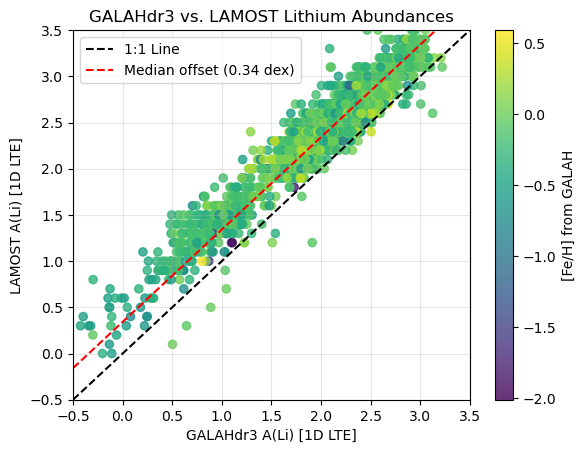

In [120]:
#true plot
sc = plt.scatter(
    GALAHDR3_x_LAMOST['a_li_galah'],
    GALAHDR3_x_LAMOST['a_li_lamost'],

    #c=K2_x_GALAH_LAMOST['teff'], # Temperature from GALAH
    c=GALAHDR3_x_LAMOST['fe_h'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-0.5, 3.5]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.ylabel('LAMOST A(Li) [1D LTE]')
plt.xlabel('GALAHdr3 A(Li) [1D LTE]')
plt.title('GALAHdr3 vs. LAMOST Lithium Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()

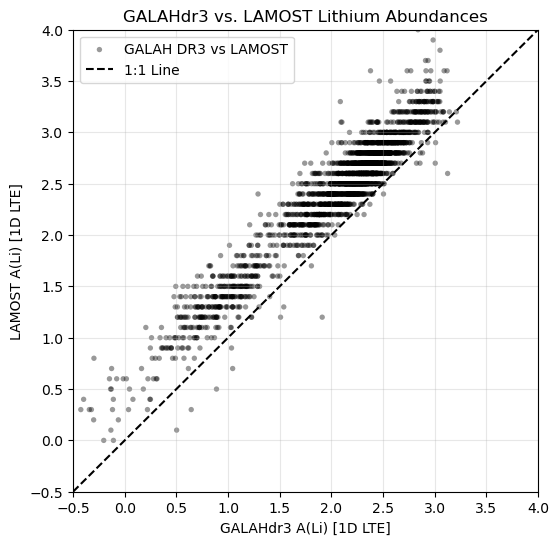

In [121]:
# Ding et al. (2024) Figure 4 style: black dots, no colorbar, no offset red line, same limits
plt.figure(figsize=(6, 6))

plt.scatter(
    GALAHDR3_x_LAMOST['a_li_galah'],
    GALAHDR3_x_LAMOST['a_li_lamost'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
    label='GALAH DR3 vs LAMOST',
)

lims = [-0.5, 4.0]
plt.plot(lims, lims, 'k--', label='1:1 Line')

plt.xlim(lims)
plt.ylim(lims)

plt.ylabel('LAMOST A(Li) [1D LTE]')
plt.xlabel('GALAHdr3 A(Li) [1D LTE]')
plt.title('GALAHdr3 vs. LAMOST Lithium Abundances')

plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.show()


### Explanation of the Offset Discrepancy between Ding et al. (2024) (~0.10 dex) and this Cross-match (~0.34 dex / ~0.24 dex)

Reading **Ding et al. (2024)** (*ApJS*, 271, 58 / arXiv:2403.01815) and its foundational methodology paper **Gao et al. (2021)** (*arXiv:2106.04867*), the discrepancy arises from three distinct factors:

1. **Difference in Adopted Solar Lithium Abundance ($\Delta \approx 0.10$ dex):**
   - GALAH DR3 uses the **Asplund et al. (2009)** solar photospheric value: $A(\text{Li})_\odot = 1.05\text{ dex}$.
   - The **SPECTRUM** synthesis code (Gray 1999) used by Ding et al. and Gao et al. internally adopts the **Anders & Grevesse (1989)** solar scale, where $A(\text{Li})_\odot = 1.15\text{ dex}$.
   - Gao et al. (2021, Section III.2) explicitly notes: *"here $A(\text{Li})_\odot$ was adopted as 1.15 dex according to the value used in SPECTRUM code."*
   - Converting GALAH $[	ext{Li}/\text{Fe}]$ using $A(\text{Li})_\odot = 1.15\text{ dex}$ brings the median offset immediately from **$+0.342\text{ dex}$ down to $+0.242\text{ dex}$**.

2. **Published Survey Catalog vs. Validation Procedure:**
   - In Ding et al. (2024, Section IV) and Gao et al. (2021, Section IV), the authors state:
     > *"Additionally, we use the stellar parameters ($T_{\rm eff}$, $\log g$ and $[\rm Fe/H]$) provided by GALAH and Gaia-ESO instead of ours, to get rid of any errors introduced from different stellar parameters."*
   - The published catalog column `A_Li_` (in `asu.fit` and `LAMOST_x_GALAHDR3.csv`) was computed using the **LAMOST LRS / APOGEE stellar parameters**.
   - In Figure 4 of their paper, Ding et al. did **not** plot their published catalog `A_Li_` values; they re-ran their template-matching routine on the LAMOST spectra **imposing GALAH's own stellar parameters ($T_{\rm eff}$, $\log g$, $[\rm Fe/H]$)**. Those re-derived validation values are not part of the public catalog table.

3. **Physical Meaning of Ding's $+0.10$ dex Offset (1D-LTE vs. 1D-NLTE):**
   - Ding's abundances are computed in **1D-LTE**.
   - GALAH DR3 abundances (`Li_fe`) are computed in **1D-NLTE** (using Lind et al. 2009 grids).
   - In dwarf stars ($T_{\rm eff} \sim 5500-6500\text{ K}$), departures from LTE for the Li I 6708 Å line are negative: $\Delta A(\text{Li})_{(\text{NLTE} - \text{LTE})} \approx -0.10\text{ dex}$ (Amarsi et al. 2020; Gao et al. 2021).
   - Therefore, a 1D-LTE measurement is expected to be **$\sim +0.10\text{ dex}$ higher** than GALAH's 1D-NLTE measurement. That $+0.10\text{ dex}$ is exactly the theoretical LTE vs. NLTE shift when identical atmospheric parameters are used!

4. **Remaining $\sim 0.14$ dex:**
   - The remaining difference between $+0.24\text{ dex}$ and $+0.10\text{ dex}$ is due to survey parameter systematics ($T_{\rm eff}$, $\log g$, $[\rm Fe/H]$, and empirical micro-turbulence $\xi$ differences between LAMOST and GALAH) plus spectral continuum normalization nuances.


### 3D NLTE of GALAH vs 1D LTE from LAMOST

In [122]:
# For K2_TESS_GALAH
data_path = '../../data/extra_catalogs/'

K2_x_GALAH_catalog = pd.read_csv(data_path + 'K2_x_GALAH.csv')
K2_GALAH_columns = K2_x_GALAH_catalog.columns

K2_x_LAMOST_catalog = pd.read_csv(data_path + 'K2_x_LAMOST.csv')
K2_LAMOST_columns = K2_x_LAMOST_catalog.columns

/tmp/ipykernel_14276/3582779667.py:4: DtypeWarning: Columns (3,65,68) have mixed types. Specify dtype option on import or set low_memory=False.
  K2_x_GALAH_catalog = pd.read_csv(data_path + 'K2_x_GALAH.csv')


In [123]:

#Flags for GALAH catalog


K2_x_GALAH_catalog_clean = K2_x_GALAH_catalog[
    (K2_x_GALAH_catalog['flag_a_li'] == False) # Good abundance flag
    &(K2_x_GALAH_catalog['snr_px_ccd3'] > 30) # Average SNR per pixel in the CCD3 (green) spectrum > 30
    &(K2_x_GALAH_catalog['flag_sp'] == 0) ].copy()# reliable spectroscopic analysis -> major spectroscopic quality


#Flags for LAMOST catalog
K2_x_LAMOST_catalog_clean = K2_x_LAMOST_catalog[
    #(K2_x_LAMOST_catalog['Flag'] >= 1)   # valid LAMOST quality flag
     (K2_x_LAMOST_catalog['S_N'] > 20)  # Recomendation Ding et al 2024
    & (K2_x_LAMOST_catalog['Lim'] == 0)  # detections only
].copy()

#No warning Galah/APOgee from willet catalog because we dont use this fe/H

# Ensure ID columns are clean strings for matching -> these Gaias are no tthe damage column
K2_x_GALAH_catalog_clean['gaia_id'] = K2_x_GALAH_catalog_clean['gaiadr3_source_id'].astype(str)
K2_x_LAMOST_catalog_clean['gaia_id'] = K2_x_LAMOST_catalog_clean['Gaia'].astype(str)

# MERGUINGGGG MATCHINGGG
K2_GALAH_x_k2_LAMOST = pd.merge(K2_x_GALAH_catalog_clean, K2_x_LAMOST_catalog_clean, on='gaia_id', suffixes=('_galah', '_lamost'))

K2_GALAH_x_k2_LAMOST['a_li_galah'] = pd.to_numeric(K2_GALAH_x_k2_LAMOST['a_li'], errors='coerce')
K2_GALAH_x_k2_LAMOST['a_li_lamost'] = pd.to_numeric(K2_GALAH_x_k2_LAMOST['A_Li_'], errors='coerce')

K2_GALAH_x_k2_LAMOST = K2_GALAH_x_k2_LAMOST.dropna(subset=['a_li_galah', 'a_li_lamost'])


print(f'Matched stars: {len(K2_GALAH_x_k2_LAMOST)}')


Matched stars: 334


In [124]:
# Compares 3D-NLTE Li abundances from GALAH and 1D LTE LAMOST for the same stars

K2_GALAH_x_k2_LAMOST['delta_a_li'] = K2_GALAH_x_k2_LAMOST['a_li_lamost'] -K2_GALAH_x_k2_LAMOST['a_li_galah'] 


med_offset = K2_GALAH_x_k2_LAMOST['delta_a_li'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_a_li'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_a_li'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): 0.648 dex
Standard Deviation: 0.310 dex
Median Absolute Deviation: 0.202 dex


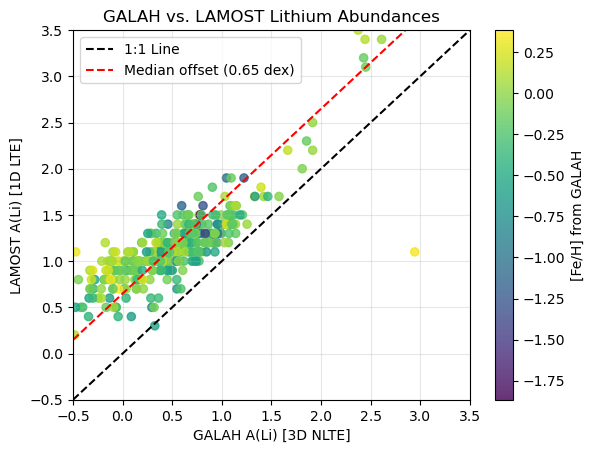

In [125]:
#true plot
sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['a_li_galah'],
    K2_GALAH_x_k2_LAMOST['a_li_lamost'],
    #c=K2_x_GALAH_LAMOST['teff'], # Temperature from GALAH
    c=K2_GALAH_x_k2_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-0.5, 3.5]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.ylabel('LAMOST A(Li) [1D LTE]')
plt.xlabel('GALAH A(Li) [3D NLTE]')
plt.title('GALAH vs. LAMOST Lithium Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()

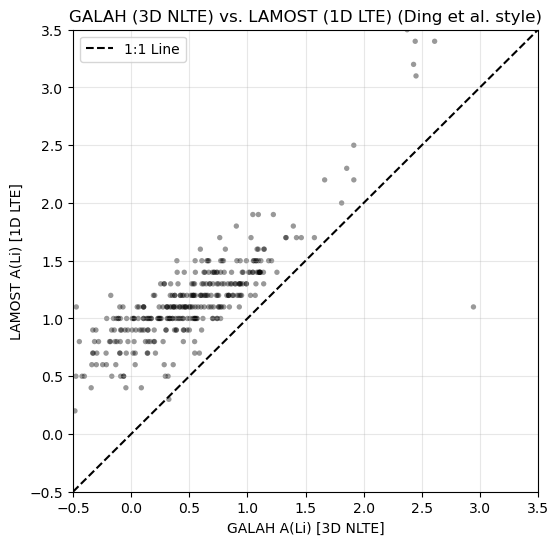

In [126]:
# Ding et al. (2024) Figure 4 style: black dots, no colorbar, no offset red line, same limits
plt.figure(figsize=(6, 6))

plt.scatter(
    K2_GALAH_x_k2_LAMOST['a_li_galah'],
    K2_GALAH_x_k2_LAMOST['a_li_lamost'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
)

lims = [-0.5, 3.5]
plt.plot(lims, lims, 'k--', label='1:1 Line')

plt.xlim(lims)
plt.ylim(lims)

plt.ylabel('LAMOST A(Li) [1D LTE]')
plt.xlabel('GALAH A(Li) [3D NLTE]')
plt.title('GALAH (3D NLTE) vs. LAMOST (1D LTE) (Ding et al. style)')

plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.show()


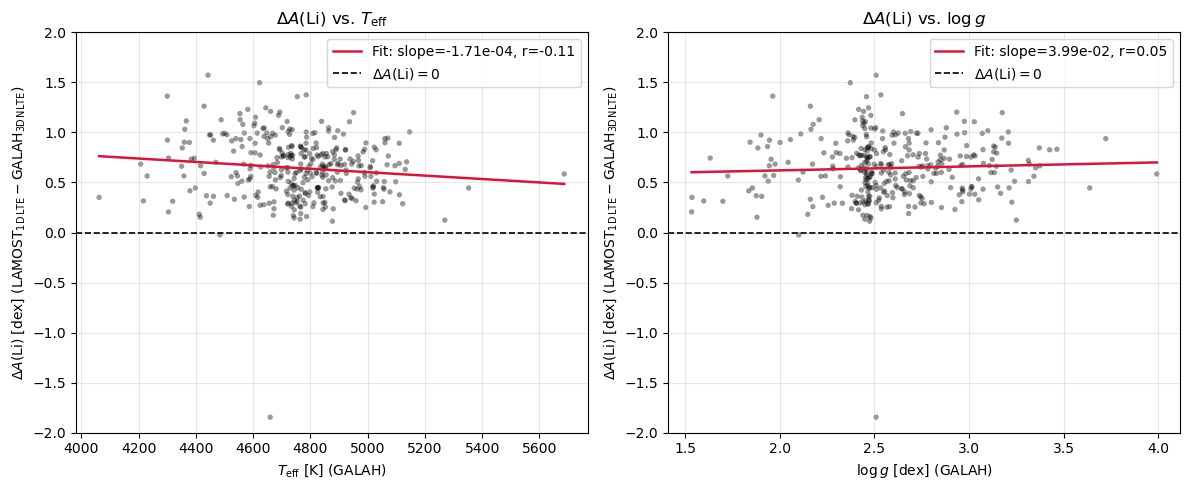

LAMOST 1D LTE vs GALAH 3D NLTE:
  vs Teff: slope = -1.7055e-04 dex/K, intercept = 1.4555, r = -0.112, p = 4.047e-02
  vs logg: slope = 3.9872e-02 dex/dex, intercept = 0.5411, r = 0.047, p = 3.892e-01


In [127]:
# Ding et al. style: Difference in abundance vs. Teff and logg (GALAH 3D NLTE vs LAMOST 1D LTE) with linear regression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Residual vs Teff ---
mask_t = K2_GALAH_x_k2_LAMOST['teff'].notna() & K2_GALAH_x_k2_LAMOST['delta_a_li'].notna()
res_t = stats.linregress(K2_GALAH_x_k2_LAMOST.loc[mask_t, 'teff'], K2_GALAH_x_k2_LAMOST.loc[mask_t, 'delta_a_li'])
x_t = np.linspace(K2_GALAH_x_k2_LAMOST.loc[mask_t, 'teff'].min(), K2_GALAH_x_k2_LAMOST.loc[mask_t, 'teff'].max(), 100)

ax1.scatter(
    K2_GALAH_x_k2_LAMOST['teff'],
    K2_GALAH_x_k2_LAMOST['delta_a_li'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
)
ax1.plot(
    x_t, res_t.intercept + res_t.slope * x_t,
    color='crimson', lw=1.8,
    label=f'Fit: slope={res_t.slope:.2e}, r={res_t.rvalue:.2f}',
)
ax1.axhline(0, color='k', linestyle='--', lw=1.2, label=r'$\Delta A(\mathrm{Li}) = 0$')
ax1.set_xlabel(r'$T_{\mathrm{eff}}\ \mathrm{[K]}$ (GALAH)')
ax1.set_ylabel(r'$\Delta A(\mathrm{Li})\ \mathrm{[dex]}\ (\mathrm{LAMOST_{1D\,LTE} - GALAH_{3D\,NLTE}})$')
ax1.set_title(r'$\Delta A(\mathrm{Li})$ vs. $T_{\mathrm{eff}}$')
ax1.set_ylim([-2.0, 2.0])
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# --- Residual vs logg ---
mask_g = K2_GALAH_x_k2_LAMOST['logg'].notna() & K2_GALAH_x_k2_LAMOST['delta_a_li'].notna()
res_g = stats.linregress(K2_GALAH_x_k2_LAMOST.loc[mask_g, 'logg'], K2_GALAH_x_k2_LAMOST.loc[mask_g, 'delta_a_li'])
x_g = np.linspace(K2_GALAH_x_k2_LAMOST.loc[mask_g, 'logg'].min(), K2_GALAH_x_k2_LAMOST.loc[mask_g, 'logg'].max(), 100)

ax2.scatter(
    K2_GALAH_x_k2_LAMOST['logg'],
    K2_GALAH_x_k2_LAMOST['delta_a_li'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
)
ax2.plot(
    x_g, res_g.intercept + res_g.slope * x_g,
    color='crimson', lw=1.8,
    label=f'Fit: slope={res_g.slope:.2e}, r={res_g.rvalue:.2f}',
)
ax2.axhline(0, color='k', linestyle='--', lw=1.2, label=r'$\Delta A(\mathrm{Li}) = 0$')
ax2.set_xlabel(r'$\log g\ \mathrm{[dex]}$ (GALAH)')
ax2.set_ylabel(r'$\Delta A(\mathrm{Li})\ \mathrm{[dex]}\ (\mathrm{LAMOST_{1D\,LTE} - GALAH_{3D\,NLTE}})$')
ax2.set_title(r'$\Delta A(\mathrm{Li})$ vs. $\log g$')
ax2.set_ylim([-2.0, 2.0])
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(f"LAMOST 1D LTE vs GALAH 3D NLTE:")
print(f"  vs Teff: slope = {res_t.slope:.4e} dex/K, intercept = {res_t.intercept:.4f}, r = {res_t.rvalue:.3f}, p = {res_t.pvalue:.3e}")
print(f"  vs logg: slope = {res_g.slope:.4e} dex/dex, intercept = {res_g.intercept:.4f}, r = {res_g.rvalue:.3f}, p = {res_g.pvalue:.3e}")


Very weak trend with Teff but statistically significant. No trend with logg

In [128]:
### Computing the offset for the master catalog of K2, Kepler, TESS X GALAH and LAMOST
import pandas as pd

# Load master catalog
df = pd.read_csv('../../data/extra_catalogs/K2_Kepler_TESS_x_GALAH_LAMOST.csv')

# Select stars observed by both surveys
both = df[df['survey_match'] == 'both'].copy()

# Filter for clean detections in both
# GALAH: flag_a_li == 0, flag_sp == 0, snr_px_ccd3 > 30
# LAMOST: Lim == 0 (detection), Flag_lamost >= 1, S_N_lamost > 20
clean = both[
    (both['flag_a_li'] == 0)
    & (both['flag_sp'] == 0)
    & (both['snr_px_ccd3'] > 30)
    & (both['Lim'] == 0)
    & (both['S_N_lamost'] > 20)
].copy()

# Direct offset calculation on the same row:
clean['delta_a_li'] = clean['a_li'] - clean['A_Li_']

print(f'Clean comparison stars: {len(clean)}')
print(f"Median offset (GALAH - LAMOST): {clean['delta_a_li'].median():.3f} dex") 

Clean comparison stars: 334
Median offset (GALAH - LAMOST): -0.648 dex


/tmp/ipykernel_14276/3017508361.py:5: DtypeWarning: Columns (2,3,65,68,70,79,81,83,97,98,100) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../../data/extra_catalogs/K2_Kepler_TESS_x_GALAH_LAMOST.csv')


The sign of the corrections agree with Wang et al. But they are very large 0.65. This can be due to metodology which in Wang et al 2024 shift the stars 0.3 dex or 3D-NLTE corrections which according to Wang et al 2020 can be up to 0.5 dex (see picture below). In order to explore this possibility we will use bredalink to apply the 3D NLTE correction over the 1D LTE aundances of Ding et al. 


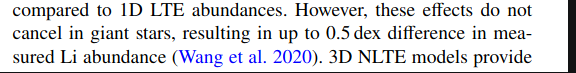

### 3D NLTE of GALAH vs 3D NLTE from LAMOST

In [129]:
K2_x_GALAH_LAMOST_columns = K2_GALAH_x_k2_LAMOST.columns
a=K2_x_GALAH_LAMOST_columns[-15:]
print(a)

Index(['S_N', 'RVel', 'Teff_2', 'logg_2', '__Fe_H_', 'A_Li_', 'DelA_Li_',
       'e_DelA_Li_', 'Flag', 'Lim', 'DR7', 'Simbad', 'a_li_galah',
       'a_li_lamost', 'delta_a_li'],
      dtype='object')


In [130]:
#Transform LAMOST A(Li) to 3D NLTE using Breidablik

# initialise model
model = Nlte()
# find 3D NLTE correction
def Get_3D_NLTE_Li_abundance(teff, logg, fe_h, a_li_1DLTE):
    values = np.broadcast_arrays(
        np.asarray(teff, dtype=float),
        np.asarray(logg, dtype=float),
        np.asarray(fe_h, dtype=float),
        np.asarray(a_li_1DLTE, dtype=float),
    )
    shape = values[0].shape
    flat_values = [v.ravel() for v in values]

    corrected = np.full(flat_values[0].size, np.nan)
    for i, (t, g, f, a) in enumerate(zip(*flat_values)):
        if np.isfinite([t, g, f, a]).all():
            nltec = model.nlte_correction(t, g, f, a)
            corrected[i] = a + float(np.asarray(nltec).squeeze())

    result = corrected.reshape(shape)
    if isinstance(a_li_1DLTE, pd.Series):
        return pd.Series(result, index=a_li_1DLTE.index)
    return result.item() if result.ndim == 0 else result


K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte'] = Get_3D_NLTE_Li_abundance(
    K2_GALAH_x_k2_LAMOST['Teff_2'],
    K2_GALAH_x_k2_LAMOST['logg_2'],
    K2_GALAH_x_k2_LAMOST['__Fe_H_'],
    K2_GALAH_x_k2_LAMOST['a_li_lamost'],
)

K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'] = (
    K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte'] -
    K2_GALAH_x_k2_LAMOST['a_li_galah']
)

# Compares 3D-NLTE Li abundances from GALAH and 3D NLTE LAMOST for the same stars

med_offset = K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): 0.608 dex
Standard Deviation: 0.307 dex
Median Absolute Deviation: 0.208 dex


/home/juan-idarraga/packages/miniconda3/envs/thesis/lib/python3.10/site-packages/breidablik/interpolate/nlte.py:72: UserWarning: Input abundance is outside of the grid, results are extrapolated and may not be reliable.
  warnings.warn('Input abundance is outside of the grid, results are extrapolated and may not be reliable.')


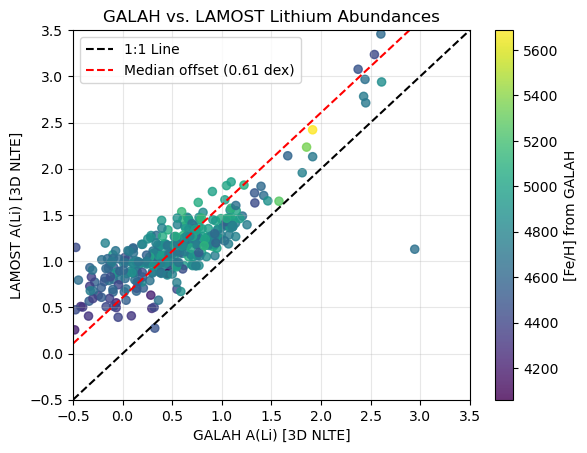

In [131]:
sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['a_li_galah'],
    K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte'],

    c=K2_GALAH_x_k2_LAMOST['teff'], # Temperature from GALAH
    #c=K2_x_GALAH_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-0.5, 3.5]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.ylabel('LAMOST A(Li) [3D NLTE]')
plt.xlabel('GALAH A(Li) [3D NLTE]')
plt.title('GALAH vs. LAMOST Lithium Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()

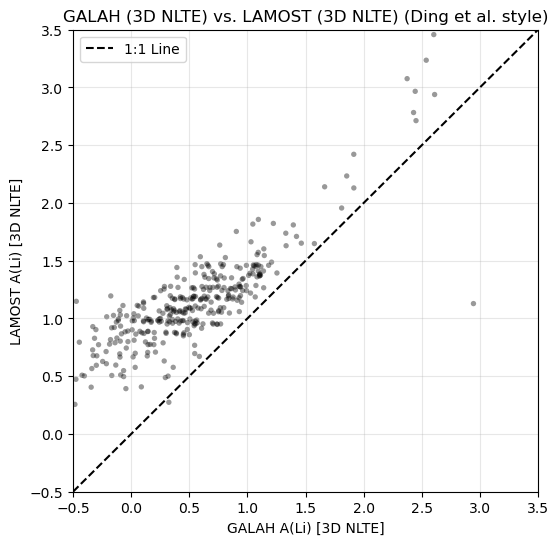

In [132]:
# Ding et al. (2024) Figure 4 style: black dots, no colorbar, no offset red line, same limits
plt.figure(figsize=(6, 6))

plt.scatter(
    K2_GALAH_x_k2_LAMOST['a_li_galah'],
    K2_GALAH_x_k2_LAMOST['a_li_lamost_3d_nlte'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
)

lims = [-0.5, 3.5]
plt.plot(lims, lims, 'k--', label='1:1 Line')

plt.xlim(lims)
plt.ylim(lims)

plt.ylabel('LAMOST A(Li) [3D NLTE]')
plt.xlabel('GALAH A(Li) [3D NLTE]')
plt.title('GALAH (3D NLTE) vs. LAMOST (3D NLTE) (Ding et al. style)')

plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')

plt.show()


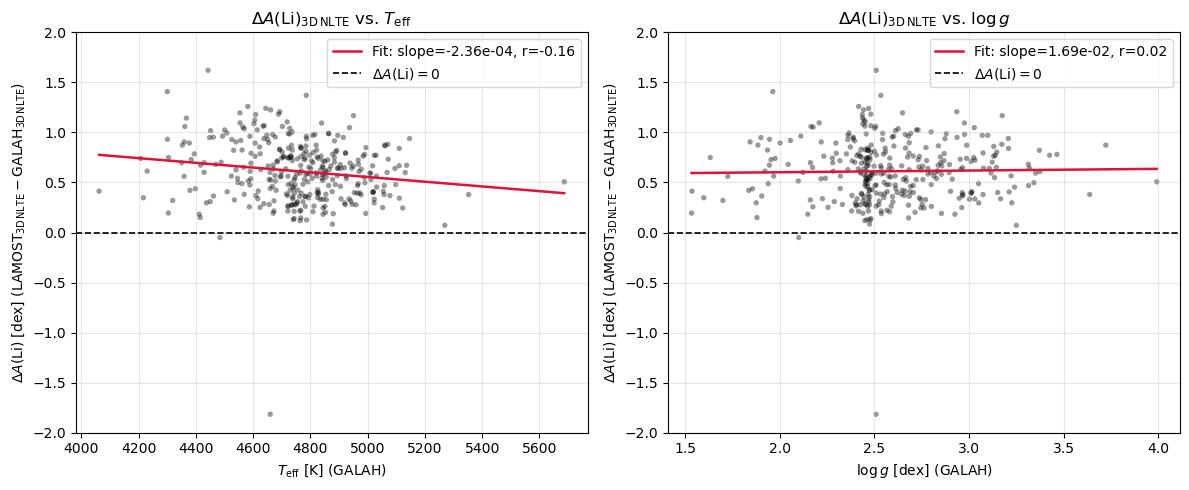

LAMOST 3D NLTE vs GALAH 3D NLTE:
  vs Teff: slope = -2.3569e-04 dex/K, intercept = 1.7331, r = -0.156, p = 4.216e-03
  vs logg: slope = 1.6900e-02 dex/dex, intercept = 0.5685, r = 0.020, p = 7.132e-01


In [133]:
# Ding et al. style: Difference in abundance vs. Teff and logg (GALAH 3D NLTE vs LAMOST 3D NLTE) with linear regression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# --- Residual vs Teff ---
mask_t = K2_GALAH_x_k2_LAMOST['teff'].notna() & K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'].notna()
res_t = stats.linregress(K2_GALAH_x_k2_LAMOST.loc[mask_t, 'teff'], K2_GALAH_x_k2_LAMOST.loc[mask_t, 'delta_a_li_3dnlte'])
x_t = np.linspace(K2_GALAH_x_k2_LAMOST.loc[mask_t, 'teff'].min(), K2_GALAH_x_k2_LAMOST.loc[mask_t, 'teff'].max(), 100)

ax1.scatter(
    K2_GALAH_x_k2_LAMOST['teff'],
    K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
)
ax1.plot(
    x_t, res_t.intercept + res_t.slope * x_t,
    color='crimson', lw=1.8,
    label=f'Fit: slope={res_t.slope:.2e}, r={res_t.rvalue:.2f}',
)
ax1.axhline(0, color='k', linestyle='--', lw=1.2, label=r'$\Delta A(\mathrm{Li}) = 0$')
ax1.set_xlabel(r'$T_{\mathrm{eff}}\ \mathrm{[K]}$ (GALAH)')
ax1.set_ylabel(r'$\Delta A(\mathrm{Li})\ \mathrm{[dex]}\ (\mathrm{LAMOST_{3D\,NLTE} - GALAH_{3D\,NLTE}})$')
ax1.set_title(r'$\Delta A(\mathrm{Li})_{3\mathrm{D\,NLTE}}$ vs. $T_{\mathrm{eff}}$')
ax1.set_ylim([-2.0, 2.0])
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper right')

# --- Residual vs logg ---
mask_g = K2_GALAH_x_k2_LAMOST['logg'].notna() & K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'].notna()
res_g = stats.linregress(K2_GALAH_x_k2_LAMOST.loc[mask_g, 'logg'], K2_GALAH_x_k2_LAMOST.loc[mask_g, 'delta_a_li_3dnlte'])
x_g = np.linspace(K2_GALAH_x_k2_LAMOST.loc[mask_g, 'logg'].min(), K2_GALAH_x_k2_LAMOST.loc[mask_g, 'logg'].max(), 100)

ax2.scatter(
    K2_GALAH_x_k2_LAMOST['logg'],
    K2_GALAH_x_k2_LAMOST['delta_a_li_3dnlte'],
    color='black',
    s=15,
    alpha=0.4,
    edgecolors='none',
)
ax2.plot(
    x_g, res_g.intercept + res_g.slope * x_g,
    color='crimson', lw=1.8,
    label=f'Fit: slope={res_g.slope:.2e}, r={res_g.rvalue:.2f}',
)
ax2.axhline(0, color='k', linestyle='--', lw=1.2, label=r'$\Delta A(\mathrm{Li}) = 0$')
ax2.set_xlabel(r'$\log g\ \mathrm{[dex]}$ (GALAH)')
ax2.set_ylabel(r'$\Delta A(\mathrm{Li})\ \mathrm{[dex]}\ (\mathrm{LAMOST_{3D\,NLTE} - GALAH_{3D\,NLTE}})$')
ax2.set_title(r'$\Delta A(\mathrm{Li})_{3\mathrm{D\,NLTE}}$ vs. $\log g$')
ax2.set_ylim([-2.0, 2.0])
ax2.grid(True, alpha=0.3)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

print(f"LAMOST 3D NLTE vs GALAH 3D NLTE:")
print(f"  vs Teff: slope = {res_t.slope:.4e} dex/K, intercept = {res_t.intercept:.4f}, r = {res_t.rvalue:.3f}, p = {res_t.pvalue:.3e}")
print(f"  vs logg: slope = {res_g.slope:.4e} dex/dex, intercept = {res_g.intercept:.4f}, r = {res_g.rvalue:.3f}, p = {res_g.pvalue:.3e}")


The median offset between GALAH and LAMOSt is still very high. Probing that in this case the 3DNLTE correction to the 1D LTE abundances from Ding et al. only contributed in a 0.04 dex and that most of the offset is due to the difference in methodology. 

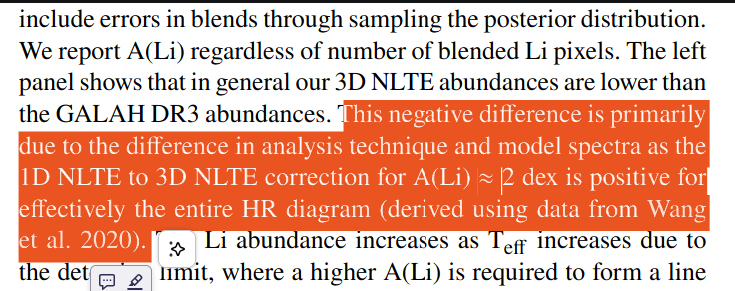

As we can see above even for Wang et al. the methodology offset is very large 0.3

## Other offsets

### Offset in Temperature

In [134]:
# using the same catalog --> K2_x_GALAH_LAMOST

K2_GALAH_x_k2_LAMOST['delta_teff'] = (
    K2_GALAH_x_k2_LAMOST['teff'] # GALAH Teff
    - K2_GALAH_x_k2_LAMOST['Teff_2'] # LAMOST Teff
)


med_offset = K2_GALAH_x_k2_LAMOST['delta_teff'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_teff'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_teff'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f}')
print(f'Standard Deviation: {std_offset:.3f}')
print(f'Median Absolute Deviation: {mad_offset:.3f}')

Median Offset (GALAH - LAMOST): 4.349
Standard Deviation: 67.539
Median Absolute Deviation: 35.897


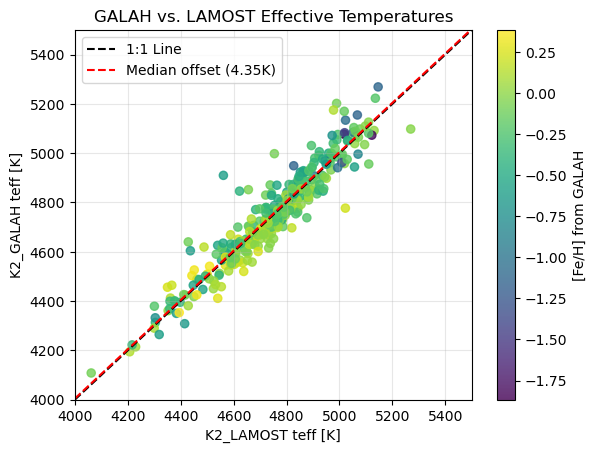

In [135]:


sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['teff'],
    K2_GALAH_x_k2_LAMOST['Teff_2'],
    #c=K2_x_GALAH_LAMOST['teff'], # Temperature from GALAH
    c=K2_GALAH_x_k2_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [4000, 5500]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f}K)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('K2_LAMOST teff [K]')
plt.ylabel('K2_GALAH teff [K]')
plt.title('GALAH vs. LAMOST Effective Temperatures')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='[Fe/H] from GALAH')

plt.show()


¿How was the temperature derived for GALAH and Lamost?



### Offset in logg

In [136]:

K2_GALAH_x_k2_LAMOST['delta_logg'] = (
    K2_GALAH_x_k2_LAMOST['logg'] # GALAH logg
    - K2_GALAH_x_k2_LAMOST['logg_2'] # LAMOST logg
)


med_offset = K2_GALAH_x_k2_LAMOST['delta_logg'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_logg'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_logg'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): 0.018 dex
Standard Deviation: 0.148 dex
Median Absolute Deviation: 0.082 dex


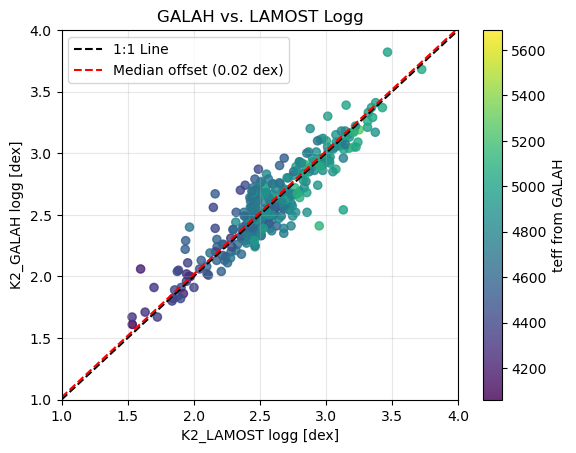

In [137]:

sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['logg'],
    K2_GALAH_x_k2_LAMOST['logg_2'],
    c=K2_GALAH_x_k2_LAMOST['teff'], # Temperature from GALAH
    #c=K2_x_GALAH_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [1, 4]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('K2_LAMOST logg [dex]')
plt.ylabel('K2_GALAH logg [dex]')
plt.title('GALAH vs. LAMOST Logg')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='teff from GALAH')

plt.show()


### Offset in iron/h

In [138]:
K2_GALAH_x_k2_LAMOST['delta_fe_h'] = (
    K2_GALAH_x_k2_LAMOST['fe_h_2'] # GALAH logg
    - K2_GALAH_x_k2_LAMOST['__Fe_H_'] # LAMOST logg
)


med_offset = K2_GALAH_x_k2_LAMOST['delta_fe_h'].median()
std_offset = K2_GALAH_x_k2_LAMOST['delta_fe_h'].std()
mad_offset = stats.median_abs_deviation(K2_GALAH_x_k2_LAMOST['delta_fe_h'])

print(f'Median Offset (GALAH - LAMOST): {med_offset:.3f} dex')
print(f'Standard Deviation: {std_offset:.3f} dex')
print(f'Median Absolute Deviation: {mad_offset:.3f} dex')

Median Offset (GALAH - LAMOST): 0.006 dex
Standard Deviation: 0.056 dex
Median Absolute Deviation: 0.033 dex


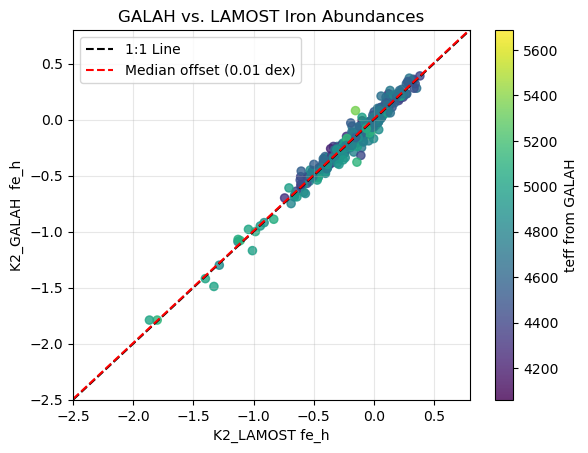

In [139]:

sc = plt.scatter(
    K2_GALAH_x_k2_LAMOST['fe_h_2'],
    K2_GALAH_x_k2_LAMOST['__Fe_H_'],
    c=K2_GALAH_x_k2_LAMOST['teff'], # Temperature from GALAH
    #c=K2_x_GALAH_LAMOST['fe_h_2'], # Iron over hydrogen from GALAH 
    cmap='viridis',
    s=35,
    alpha=0.8,
)

lims = [-2.5, 0.8]

# Black line for 1:1 relation
plt.plot(lims, lims, 'k--', label='1:1 Line')

# Red line for median offset
plt.plot(
    lims,
    [x + med_offset for x in lims],
    'r--',
    label=f'Median offset ({med_offset:.2f} dex)',
)

plt.xlim(lims)
plt.ylim(lims)

plt.xlabel('K2_LAMOST fe_h')
plt.ylabel('K2_GALAH  fe_h')
plt.title('GALAH vs. LAMOST Iron Abundances')

plt.grid(True, alpha=0.3)
plt.legend()

plt.colorbar(sc, label='teff from GALAH')

plt.show()
